## Funciones de membresía (trapezoidales)
Ejemplo de nuestra presentación:
- Uso del CPU: Muy Bajo, Bajo, Medio, Alto, Muy Alto
- Tiempo de respuesta: Rápido, Normal, Lento, Crítico
- Ajuste de recursos: Ninguno, Bajo, Moderado, Alto, Máximo

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import fuzzy
%matplotlib inline

cpu_universe = np.linspace(0, 100, 101)
time_universe = np.linspace(0, 1000, 1001)
ajuste_universe = np.linspace(0, 100, 101)

## Funciones de membresía (trapezoidales)
Ejemplo de nuestra presentación:
- Uso del CPU: Muy Bajo, Bajo, Medio, Alto, Muy Alto
- Tiempo de respuesta: Rápido, Normal, Lento, Crítico
- Ajuste de recursos: Ninguno, Bajo, Moderado, Alto, Máximo

In [15]:
CPU_MFs = {
    'Muy Bajo': (fuzzy.trapmf, [0, 0, 10, 25]),
    'Bajo'    : (fuzzy.trapmf, [10, 20, 35, 45]),
    'Medio'   : (fuzzy.trapmf, [35, 45, 65, 75]),
    'Alto'    : (fuzzy.trapmf, [65, 75, 88, 95]),
    'Muy Alto': (fuzzy.trapmf, [85, 95, 100, 100]),
}

TIME_MFs = {
    'Rápido'  : (fuzzy.trapmf, [0, 0, 100, 200]),
    'Normal'  : (fuzzy.trapmf, [100, 200, 300, 450]),
    'Lento'   : (fuzzy.trapmf, [300, 450, 600, 750]),
    'Crítico' : (fuzzy.trapmf, [600, 750, 1000, 1000]),
}

AJUSTE_MFs = {
    'Ninguno' : (fuzzy.trapmf, [0, 0, 5, 15]),
    'Bajo'    : (fuzzy.trapmf, [5, 15, 30, 40]),
    'Moderado': (fuzzy.trapmf, [30, 40, 60, 70]),
    'Alto'    : (fuzzy.trapmf, [60, 70, 85, 92]),
    'Máximo'  : (fuzzy.trapmf, [85, 92, 100, 100]),
}

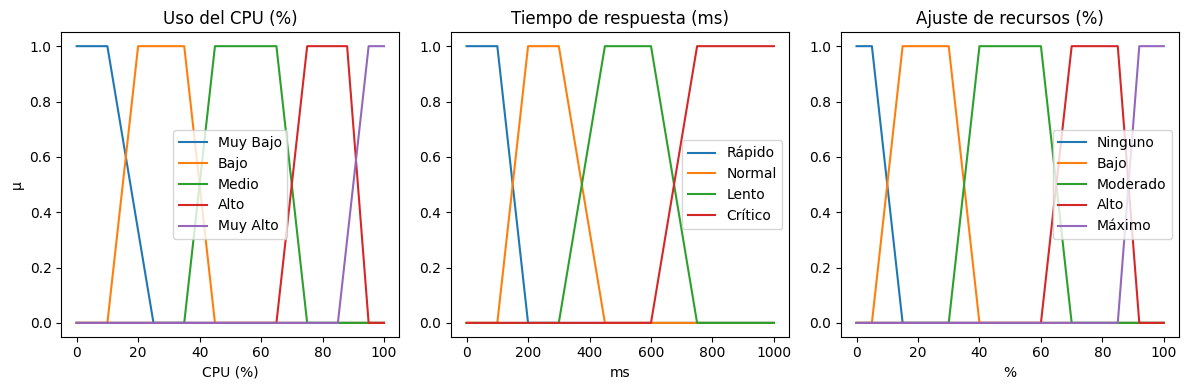

In [16]:
plt.figure(figsize=(12,4))
# CPU
plt.subplot(1,3,1)
for label,(f,p) in CPU_MFs.items():
    plt.plot(cpu_universe, f(cpu_universe,p), label=label)
plt.title("Uso del CPU (%)")
plt.xlabel("CPU (%)")
plt.ylabel("μ")
plt.legend()

# Tiempo
plt.subplot(1,3,2)
for label,(f,p) in TIME_MFs.items():
    plt.plot(time_universe, f(time_universe,p), label=label)
plt.title("Tiempo de respuesta (ms)")
plt.xlabel("ms")
plt.legend()

# Ajuste
plt.subplot(1,3,3)
for label,(f,p) in AJUSTE_MFs.items():
    plt.plot(ajuste_universe, f(ajuste_universe,p), label=label)
plt.title("Ajuste de recursos (%)")
plt.xlabel("%")
plt.legend()

plt.tight_layout()

## Reglas difusas
Generamos reglas combinando etiquetas de CPU y Tiempo.
La conjunción "Y" se evalúa con `min()`. 
El consecuente se recorta por el grado de activación (método CUT).
La agregación de todas las reglas se hace por `max()` y la defuzzificación por `centroid`.
(Se usa una heurística que prioriza CPU al decidir el ajuste).

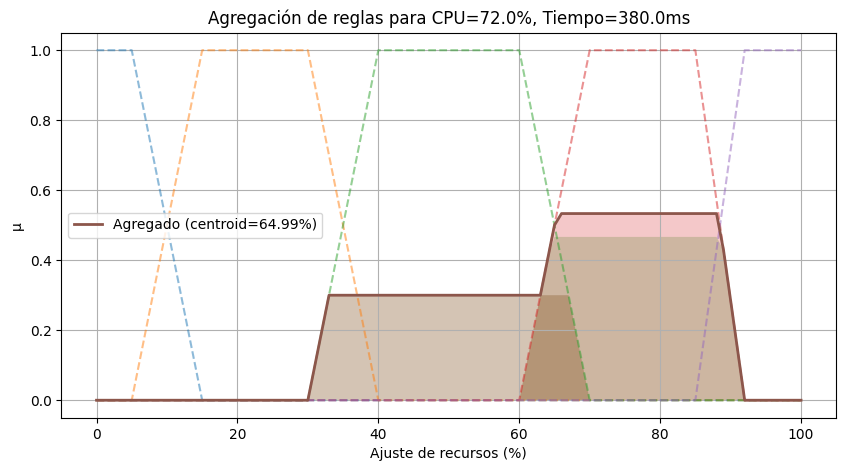

Ajuste defuzzificado: 64.99334811529928
Ajuste defuzzificado: 64.99 %


In [ ]:
from control_caso_estudio import infer

ajuste_crisp, aggregated, details, cpu_grados, time_grados = infer(72.0, 380.0, plot=True)
# Ajuste sin límite de decimales
print("Ajuste defuzzificado:", ajuste_crisp)
# Ajuste a dos decimales
print("Ajuste defuzzificado: {:.2f} %".format(ajuste_crisp))

In [13]:
print("Membresías CPU (72%):")
for k,v in cpu_grados.items():
    print(f"{k:8s}: {v:.4f}")
print("\nMembresías Tiempo (380ms):")
for k,v in time_grados.items():
    print(f"{k:8s}: {v:.4f}")

print("\nReglas activadas (Top):")
details_sorted = sorted(details, key=lambda x: x[3], reverse=True)
for c_label, t_label, a_label, act in details_sorted[:12]:
    print(f"SI CPU={c_label} Y Tiempo={t_label} => Ajuste={a_label} (act={act:.4f})")

Membresías CPU (72%):
Muy Bajo: 0.0000
Bajo    : 0.0000
Medio   : 0.3000
Alto    : 0.7000
Muy Alto: 0.0000

Membresías Tiempo (380ms):
Rápido  : 0.0000
Normal  : 0.4667
Lento   : 0.5333
Crítico : 0.0000

Reglas activadas (Top):
SI CPU=Alto Y Tiempo=Lento => Ajuste=Alto (act=0.5333)
SI CPU=Alto Y Tiempo=Normal => Ajuste=Alto (act=0.4667)
SI CPU=Medio Y Tiempo=Normal => Ajuste=Moderado (act=0.3000)
SI CPU=Medio Y Tiempo=Lento => Ajuste=Moderado (act=0.3000)


## Conclusión
- El sistema difuso determinó un ajuste de recursos de aproximadamente X% (valor mostrado).
- Interpretación: si el ajuste es alto, se recomienda escalar recursos (por ejemplo, más instancias o más CPU).
- Ventajas de usar lógica difusa: modela la gradualmente de "alto" / "lento", evita umbrales abruptos.